# Imbalanced Feature Screener on SBA loans

This notebook demonstrates the `ImbalancedFeatureScreener` package on the SBA imbalanced loan dataset.

The workflow: load the cleaned imbalanced dataset, fit the screener, inspect the ranked report, then visualize the summary and a representative feature diagnostic.

## Data leakage guard

We remove `loanstatus`, `paidinfulldate`, `chargeoffdate`, and `grosschargeoffamount` from the analysis up front. These are post-outcome or outcome-derived fields that would leak the target signal into the feature set if left in the dataset.

This is a deliberate feature exclusion, not a modeling choice to be revisited later.

In [1]:
import sys
from pathlib import Path

import pandas as pd

repo_root = Path.cwd().resolve().parent
src_dir = repo_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from imb_feature_screener import ImbalancedFeatureScreener

data_path = repo_root / 'data' / 'sba_full_attrib_clean.csv'
df = pd.read_csv(data_path, low_memory=False)
# Data leakage guard: remove outcome/post-outcome status fields before screening.
# We explicitly exclude the target-like fields that encode the realized loss outcome: 
# `loanstatus`, `paidinfulldate`, `chargeoffdate`, and `grosschargeoffamount`.
# These fields would leak distress information into the candidate features.
leakage_columns = ['loanstatus', 'paidinfulldate', 'chargeoffdate', 'grosschargeoffamount']
df = df.drop(columns=[c for c in leakage_columns if c in df.columns], errors='ignore')
df = df[df['loan_status_r'] != -1].copy()
df['target'] = df['loan_status_r'].astype(int)
print(df.shape)
print(df['target'].value_counts().sort_index().to_string())
X = df.drop(columns=['loan_status_r', 'target'])
y = df['target']
print(f'Features: {len(X.columns)}')
print(f'Attributes: {list(X.columns)}')


/home/rajiv/programming/imbalanced_feature_screener/imb_feature_screener/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(75094, 41)
target
0    68201
1     6893
Features: 39
Attributes: ['asofdate', 'program', 'locationid', 'borrname', 'borrstreet', 'borrcity', 'borrstate', 'borrzip', 'bankname', 'bankfdicnumber', 'bankncuanumber', 'bankstreet', 'bankcity', 'bankstate', 'bankzip', 'grossapproval', 'sbaguaranteedapproval', 'approvaldate', 'approvalfy', 'firstdisbursementdate', 'processingmethod', 'initialinterestrate', 'fixedorvariableinterestind', 'terminmonths', 'naicscode', 'naicsdescription', 'franchisecode', 'franchisename', 'projectcounty', 'projectstate', 'sbadistrictoffice', 'congressionaldistrict', 'businesstype', 'businessage', 'revolverstatus', 'jobssupported', 'collateralind', 'soldsecmrktind', 'loan_age_months']


In [2]:
screener = ImbalancedFeatureScreener(top_k=10, n_splits=3)
screener.fit(X, y)
print(screener.report_.head(10)[['feature','iv','ks_stat','uni_pr_auc','perm_pr_auc','pos_shap','consensus_rank']].to_string(index=False))
print(f'\nSelected features: {screener.selected_features_}')


            feature       iv  ks_stat  uni_pr_auc  perm_pr_auc  pos_shap  consensus_rank
           bankname 0.287368 0.382556    0.241551     0.054723  0.240752             2.6
           bankcity 0.255257 0.359083    0.212834     0.022485  0.140635             4.4
initialinterestrate 0.172152 0.302974    0.197137     0.056980  0.221443             4.6
         bankstreet 0.289417 0.382584    0.241106     0.007168  0.038189             6.0
       terminmonths 0.425178 0.503444    0.060463     0.337758  0.870681             8.6
           borrname 0.210295 0.117156    0.177295     0.083871  0.198774             8.6
   naicsdescription 0.105336 0.234294    0.173752     0.006537  0.113374             9.2
          bankstate 0.139865 0.295574    0.188645     0.008950  0.004419            11.4
         borrstreet 0.198852 0.093196    0.156476     0.014482  0.047815            12.2
      projectcounty 0.069661 0.207647    0.163800     0.005542  0.032854            12.2

Selected features: [

In [3]:
X_selected = screener.transform(X)
print(X_selected.shape)
print(X_selected.head())


(75094, 10)
   bankname  initialinterestrate  terminmonths  borrname  naicsdescription  \
0  0.323440                11.04         120.0  0.083447          0.084149   
1  0.123167                 9.00         120.0  0.083447          0.073825   
2  0.094460                 6.99          60.0  0.083447          0.074309   
3  0.062189                 6.00          90.0  0.083447          0.073825   
4  0.108351                 7.00         120.0  0.083447          0.059258   

   bankstate  projectcounty  sbadistrictoffice  sbaguaranteedapproval  \
0   0.284093       0.102093           0.106818                12500.0   
1   0.284093       0.304233           0.255417                47900.0   
2   0.102375       0.045175           0.061533                20000.0   
3   0.050515       0.124908           0.125713               187500.0   
4   0.102375       0.095291           0.085746                50000.0   

   borrcity  
0  0.119870  
1  0.193120  
2  0.050995  
3  0.139323  
4  0.04258

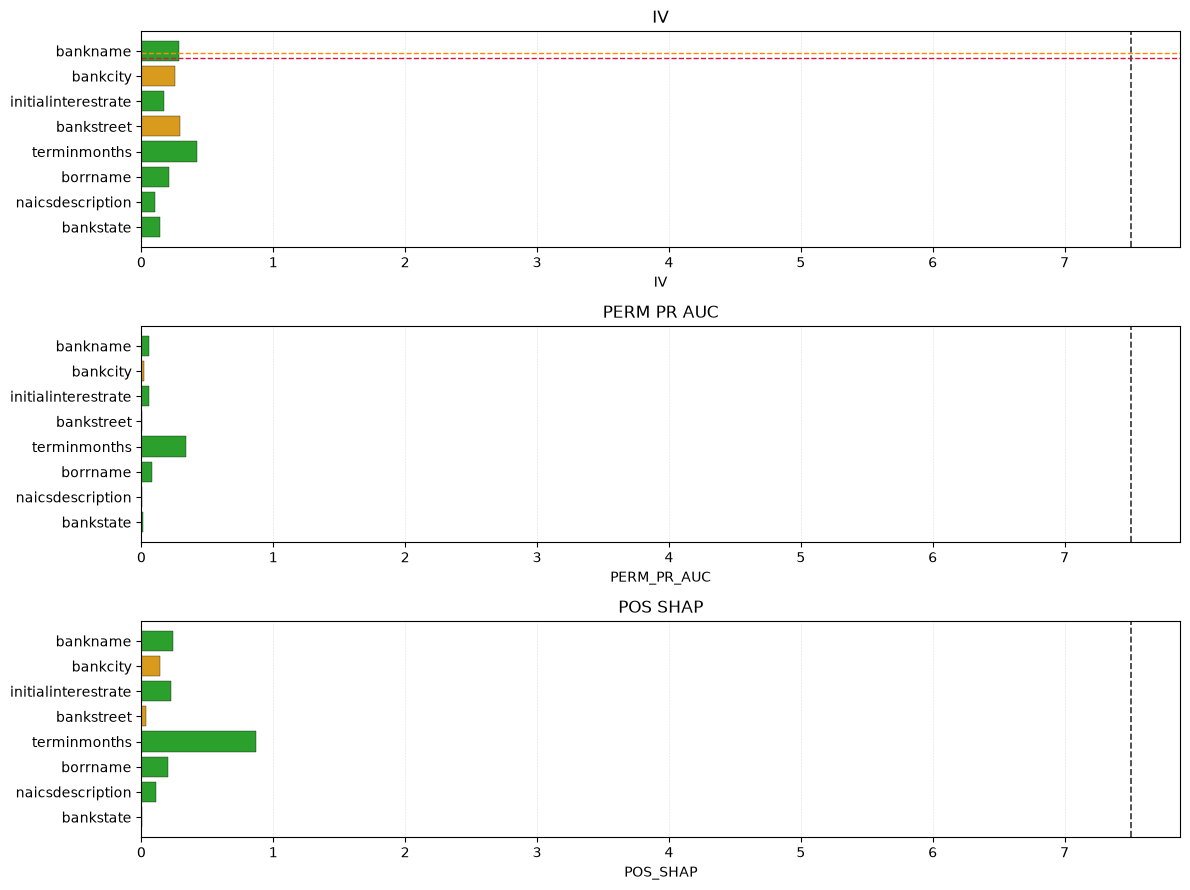

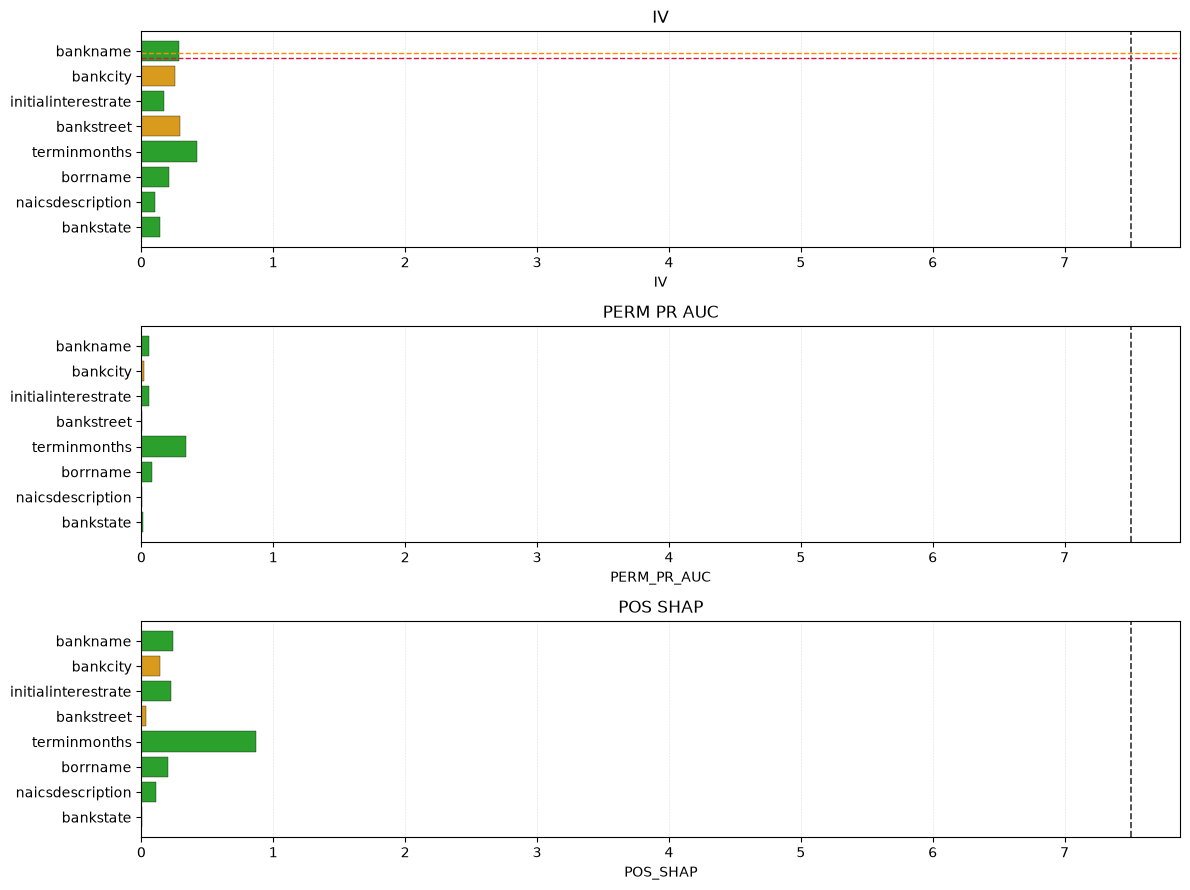

In [4]:
from IPython.display import display

summary_fig = screener.plot_summary(top_n=8)
display(summary_fig)


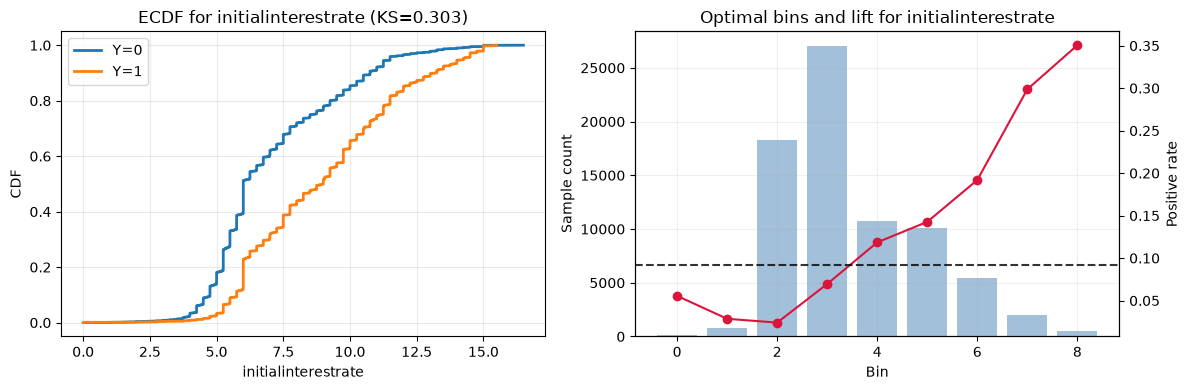

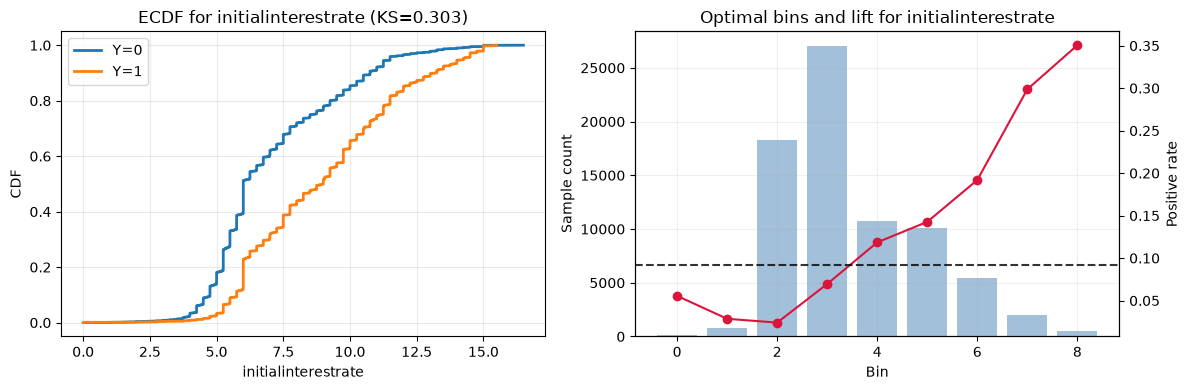

In [5]:
feature = 'initialinterestrate'
feature_fig = screener.plot_feature(X, y, feature=feature, log_x=False)
display(feature_fig)
